# STM Four-Panel Cross-Section

- Calls the co-registered 15:30–16:00 UTC segment in `/Documents/data/nurture-oe-cache/coreg_20260217_1530-1600.nc`.  
- Or simply run `scripts/run_task_d.py` first.
- This notebook is modified from `scripts/stm_fourpanel.py`.
- This supercedes the figure `docs/reports/figures/stm_20260217_1530-1600.png`.

In [1]:
import sys

import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import numpy as np
import ultraplot as uplt
uplt.rc.update(suptitlesize=20, ticklabelsize=16, fontsize=16,
              figurefacecolor='w', ticklen=8, ticklenratio=0.75)
import xarray as xr
import radar_cmaps # grabbed from the impacts_tools repo

from nurture_oe.config import REPO_ROOT, cache_dir, example_file
from nurture_oe.io.cloudcube import read_cloudcube
from nurture_oe.io.halo_aerowv import read_halo_aerowv
from nurture_oe.io.halo_cloudsurface import read_halo_cloudsurface
# sys.path.append('../src/nurture_oe')
# from io import cloudcube, halo_cloudsurface, halo_aerowv

## Plot Raw Data

In [2]:
segment = ("2026-02-17T15:30:00", "2026-02-17T16:00:00")
PAD = np.timedelta64(6, "s")
# CLEARANCES_M = (0, 60, 120, 250, 500, 1000)
HALO_VARS = ["532_total_attn_bsc", "532_dep", "gps_alt", "Temperature", "Aerosol_ID"]
HALF_WINDOW = np.timedelta64(5, "s")

t0, t1 = (np.datetime64(s, "ns") for s in segment)
halo = read_halo_aerowv(example_file("halo_aerowv"), variables=HALO_VARS, time_range=segment)
# keep only HALO profiles whose whole window lies inside the segment
halo = halo.sel(time=(halo.time - HALF_WINDOW >= t0) & (halo.time + HALF_WINDOW <= t1))
# win = coreg.halo_windows(halo.time.values)
cs = read_halo_cloudsurface(example_file("halo_cloudsurface"), variables=["Type", "altSurface"],
                            time_range=(t0 - PAD, t1 + PAD))
cc_path = example_file("cloudcube_1521")
cc = read_cloudcube(cc_path, time_range=(t0 - PAD, t1 + PAD))
# extra = {f"zgc_{b}": coreg.gas_corrected_display(cc, b) for b in ("w", "g")}
# grid = coreg.cloudcube_to_halo_grid(cc, halo, win, extra=extra)
# fr = coreg.cloudmask_fractions(cs, win)
# pm = coreg.phase_masks(fr)
with np.errstate(invalid="ignore"):
    dwr = cc["zm_w"] - cc["zm_g"]
dwr.attrs = {"long_name": "DWR W-G (measured)", "units": "dB"}
# out = xr.merge([halo, grid.drop_vars("time").assign_coords(time=halo.time),
#                 fr.drop_vars("time").assign_coords(time=halo.time),
#                 pm.drop_vars("time").assign_coords(time=halo.time).astype("int8")],
#                combine_attrs="drop")
cc["dwr_wg"] = dwr.drop_vars("time").assign_coords(time=cc.time)
sfc = np.nan_to_num(cs["altSurface"].values)[:, None]
# s, _ = coreg.window_sums(sfc, cs["time"].values, win)
# k, _ = coreg.window_sums(np.isfinite(cs["altSurface"].values)[:, None].astype(float), cs["time"].values, win)
# with np.errstate(invalid="ignore", divide="ignore"):
#     out["surface_alt_lidar"] = ("time", (s / k)[:, 0], {"long_name": "window mean of C&S altSurface", "units": "m"})

In [3]:
# Step 1
# lat, lon: 1D arrays over the time dimension, in degrees (geodetic)
phi = np.deg2rad(cc.lat)
lam = np.deg2rad(cc.lon)

# Local geodetic "up" unit vectors in ECEF, shape (time, 3)
up_ecef = np.stack([
    np.cos(phi) * np.cos(lam),   # x
    np.cos(phi) * np.sin(lam),   # y
    np.sin(phi),                 # z
], axis=1)

# Step 2
# look_vector_ecef: shape (17932, 3), unit vector, antenna -> target
# up_ecef:          shape (17932, 3), from Step 1

# Row-wise dot product -> dz/dr per profile, shape (17932,)
dzdr = np.sum(cc.look_vector_ecef.values * up_ecef, axis=1)

[alt2d, radar_range2d] = np.meshgrid(cc.alt.values, cc.range.values)
dzdr2d, _ = np.meshgrid(dzdr, cc.range.values)
hght = alt2d + dzdr2d * radar_range2d

In [4]:
def xsection_grid(x_grid, y_grid):
    '''
    Adds an extra element in the time/distance and height dimension to conform to newer mpl pcolormesh() function.
    Useful for plotting ER-2 radar cross sections.
    
    Parameters
    ----------
    x_grid: 2D time or distance field created from er2read() or resample() subroutines.
    y_grid: 2D height field created from er2read() or resample() subroutines.
    '''
    
    # Work with x coordinate (time/distance) first
    xdelta = x_grid[0, -1] - x_grid[0, -2] # should work on time and float dtypes
    vals_to_append = np.atleast_2d(np.tile(x_grid[0,-1] + xdelta, x_grid.shape[0])).T
    x_regrid = np.hstack((x_grid, vals_to_append)) # add column
    x_regrid = np.vstack((np.atleast_2d(x_regrid[0,:]), x_regrid)) # add row
    
    # Now do the y coordinate (height)
    ydelta = y_grid[0, :] - y_grid[1, :] # height difference between first and second gates
    vals_to_append = np.atleast_2d(y_grid[0,:] + ydelta)
    y_regrid = np.vstack((vals_to_append, y_grid)) # add row
    y_regrid = np.hstack((y_regrid, np.atleast_2d(y_regrid[:,-1]).T))
    
    return x_regrid, y_regrid

X2, Y2 = xsection_grid(
    np.tile(np.atleast_2d(cc.time), (len(cc.range), 1)), # 2D time
    hght / 1000. # 2D height in km
)

/var/folders/js/9036d4cd7bs_z7lq3584lr380000gp/T/ipykernel_39467/2877821767.py:33: UltraPlotWarning: Skipping incompatible x-axis sharing for CartesianAxes and CartesianAxes: different axis unit domains.
  cb = ax.colorbar(m, loc="r", label=units, width=0.12)


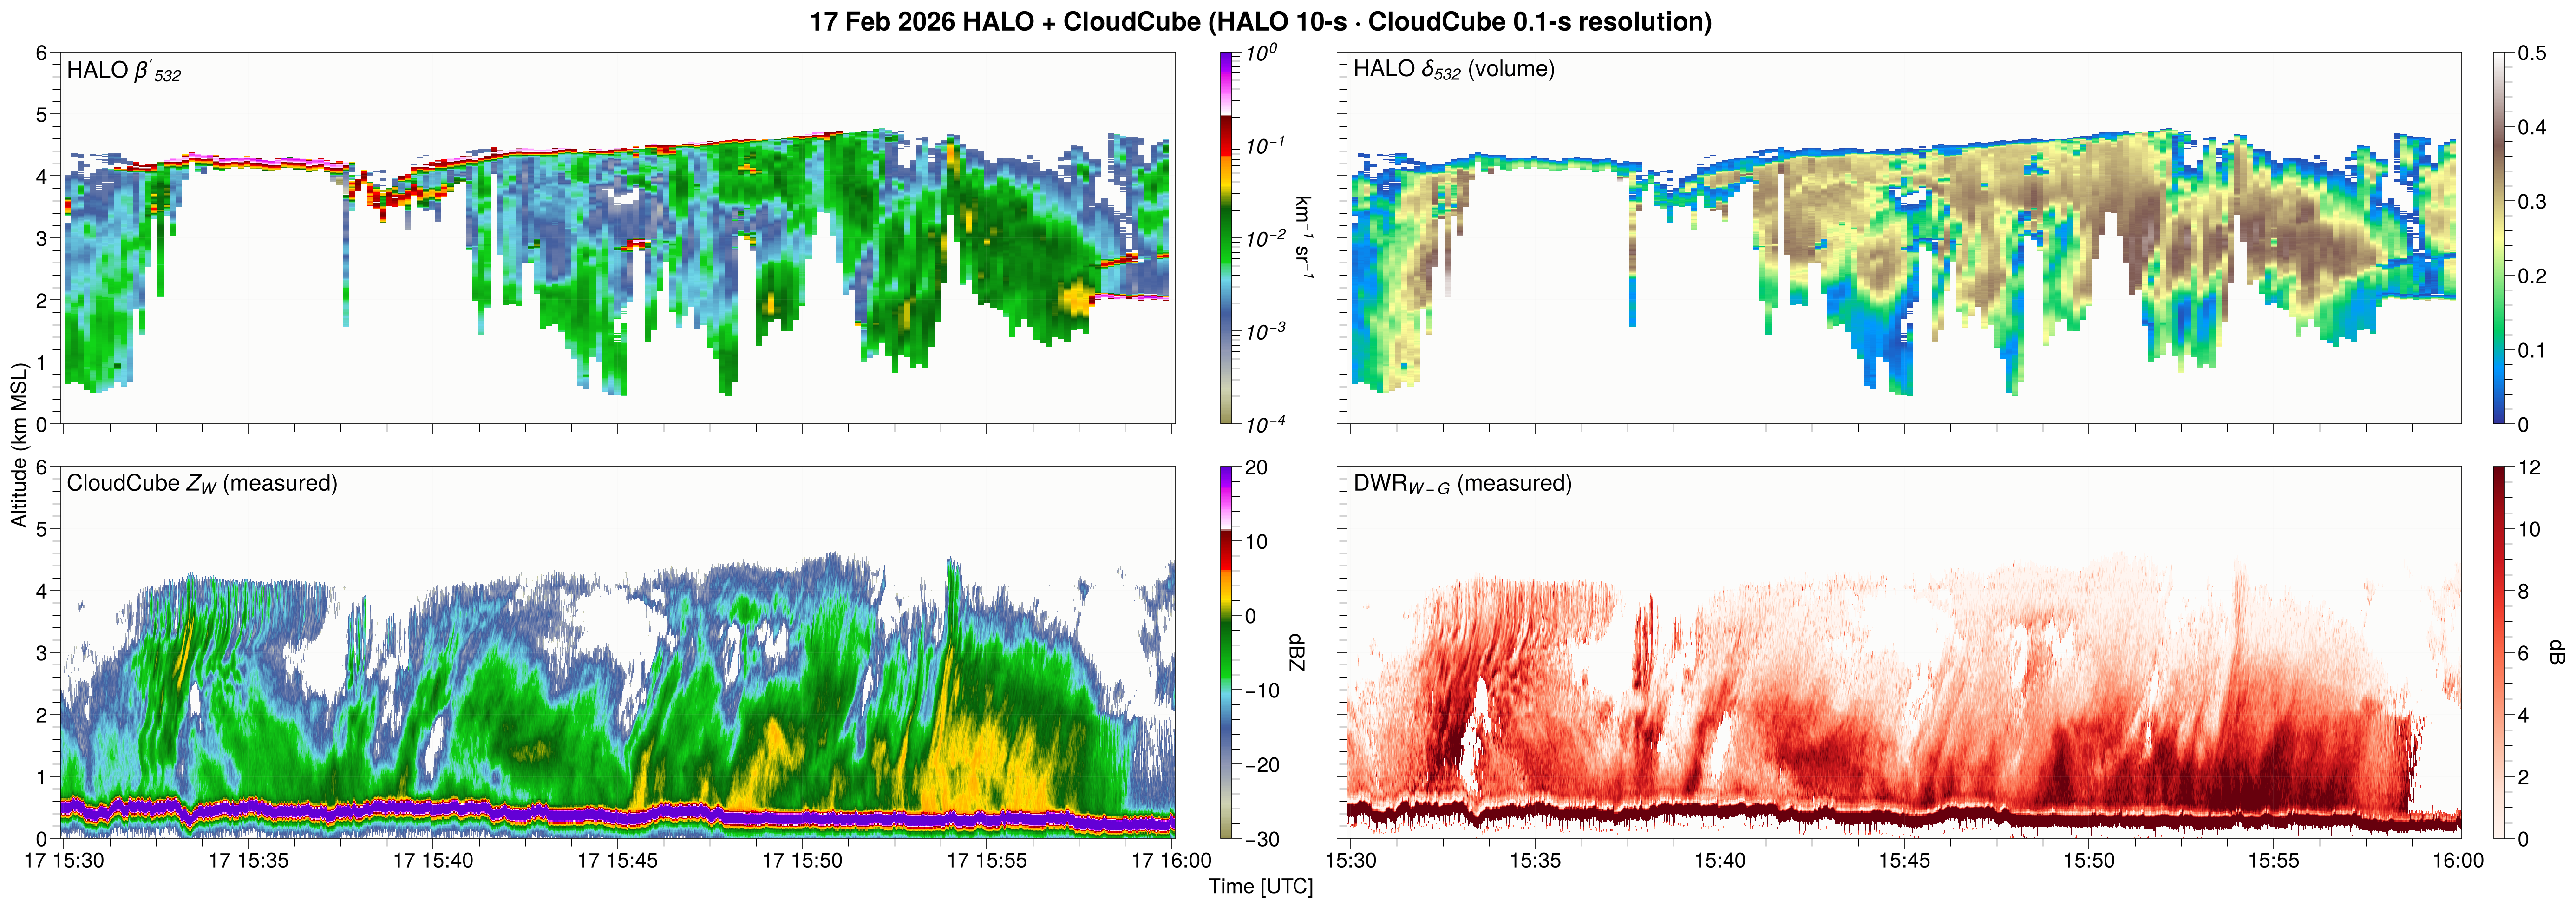

In [7]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"

panels = [
    ("532_total_attn_bsc", r"HALO $\beta'_{532}$", r"km$^{-1}$ sr$^{-1}$",
     dict(cmap="radar_NWSRefEnhanced", norm=mcolors.LogNorm(1e-4, 1e0)), [1e-4, 1e-3, 1e-2, 1e-1, 1e0]),
    ("532_dep", r"HALO $\delta_{532}$ (volume)", "",
     dict(cmap="terrain", norm=mcolors.Normalize(0, 0.5)), None),
    ("zm_w", r"CloudCube $Z_W$ (measured)", "dBZ",
     dict(cmap="radar_NWSRefEnhanced", norm=mcolors.Normalize(-30, 20)), None),
    ("dwr_wg", r"DWR$_{W-G}$ (measured)", "dB",
     dict(cmap="reds", norm=mcolors.Normalize(0, 12)), [0, 2, 4, 6, 8, 10, 12]),
     #dict(cmap=ramp(DIVERGING, "div"), norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-6, vmax=12)), [-6, -3, 0, 3, 6, 9, 12]),
]

fig, axs = uplt.subplots(nrows=2, ncols=2, refwidth=12, refaspect=3, sharex=True, sharey=True,
                         facecolor=SURFACE)
for ax, (var, title, units, kw, ticks) in zip(axs, panels):
    if var in "532_total_attn_bsc":
        t = halo["time"].values
        zkm = halo["z"].values / 1000.0
        data = halo[var].values
        data = np.where(halo["532_dep"] < 0.02, np.nan, data)
    elif var in "532_dep":
        t = halo["time"].values
        zkm = halo["z"].values / 1000.0
        data = halo[var].values
        data = np.where(halo["532_dep"] < 0.02, np.nan, data)
    elif var in ("zm_w", "dwr_wg"):
        t = X2
        zkm = Y2
        data = cc[var].values
    m = ax.pcolormesh(t, zkm, data.T, discrete=False, rasterized=True, **kw)
    cb = ax.colorbar(m, loc="r", label=units, width=0.12)
    if ticks is not None:
        cb.set_ticks(ticks)
        if var == "532_total_attn_bsc":
            cb.set_ticklabels([f"$10^{{{int(np.log10(v))}}}$" for v in ticks])
    # ax.fill_between(cs.time.values, 0, sfc[:, 0]/1000., alpha=1., color=MUTED)
    #ax.plot(t, sfc, color=MUTED, lw=1.0)
    if var == "dwr_wg_gc":
        ax.contour(t, zkm, liquid.T, levels=[0.5], colors=INK, linewidths=1.0)
    ax.format(ultitle=title, facecolor=SURFACE, gridcolor=GRID)
axs.format(ylim=(0, 6), ylabel="Altitude (km MSL)", xlabel="Time [UTC]",
           suptitle="17 Feb 2026 HALO + CloudCube (HALO 10-s · CloudCube 0.1-s resolution)"
           )
axs.format(xrotation=0)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

---

In [9]:
ds = xr.open_dataset(cache_dir() / "coreg_20260217_1530-1600.nc")
ds

<xarray.Dataset> Size: 33MB
Dimensions:             (time: 179, z: 845)
Coordinates:
  * time                (time) datetime64[ns] 1kB 2026-02-17T15:30:07 ... 202...
    time_native         (time) float64 1kB ...
    lat                 (time) float64 1kB ...
    lon                 (time) float64 1kB ...
  * z                   (z) float64 7kB -300.0 -285.0 ... 1.234e+04 1.235e+04
Data variables: (12/35)
    532_dep             (time, z) float64 1MB ...
    532_total_attn_bsc  (time, z) float64 1MB ...
    Aerosol_ID          (time, z) float32 605kB ...
    gps_alt             (time) float64 1kB ...
    Temperature         (time, z) float64 1MB ...
    n_rays              (time) int64 1kB ...
    ...                  ...
    n_sub               (time) int64 1kB ...
    cloud               (time, z) int8 151kB ...
    liquid              (time, z) int8 151kB ...
    ice                 (time, z) int8 151kB ...
    dwr_wg_gc           (time, z) float64 1MB ...
    surface_alt_lidar   (time) float64 1kB ...
Attributes: (12/18)
    title:                     HALO + CloudCube co-registered on the HALO gri...
    source_halo_aerowv:        nurture-HALO_G3_20260217_R0_L1.h5
    source_halo_cloudsurface:  NURTURE-HALO-CloudAndSurface_G3_20260217_R0_L1.h5
    source_cloudcube:          NURTURE-CLOUDCUBE_G3_20260217_R0_S20260217a152...
    nurture_oe_version:        0.1.0
    created:                   2026-10-14T15:20:39+00:00
    ...                        ...
    radar_sensitivity_g_dbz:   -37.58 dBZ @ 1 km
    zmin_1km_dbz_ka:           -16.32
    zmin_1km_dbz_w:            -32.64
    zmin_1km_dbz_g:            -37.58
    phase_rule:                liquid: class 0 in >=50% of sub-profiles; ice:...
    gas_correction:            zgc_* = zm + 2*int katten dr, display only (ap...

In [10]:
ymax_km=6.0
radar_clearance_m=250.0

t = ds["time"].values
zkm = ds["z"].values / 1000.0
liquid = ds["liquid"].values.astype(float)
sfc = ds["surface_alt_lidar"].to_series().interpolate(limit_direction="both").to_numpy() / 1000.0

# display-only: hide radar gates within radar_clearance_m of the lidar surface (surface clutter)
near_sfc = (zkm[None, :] - sfc[:, None]) * 1000.0 < radar_clearance_m

/var/folders/js/9036d4cd7bs_z7lq3584lr380000gp/T/ipykernel_39467/3834566160.py:26: UltraPlotWarning: Skipping incompatible x-axis sharing for CartesianAxes and CartesianAxes: different axis unit domains.
  cb = ax.colorbar(m, loc="r", label=units, width=0.12)


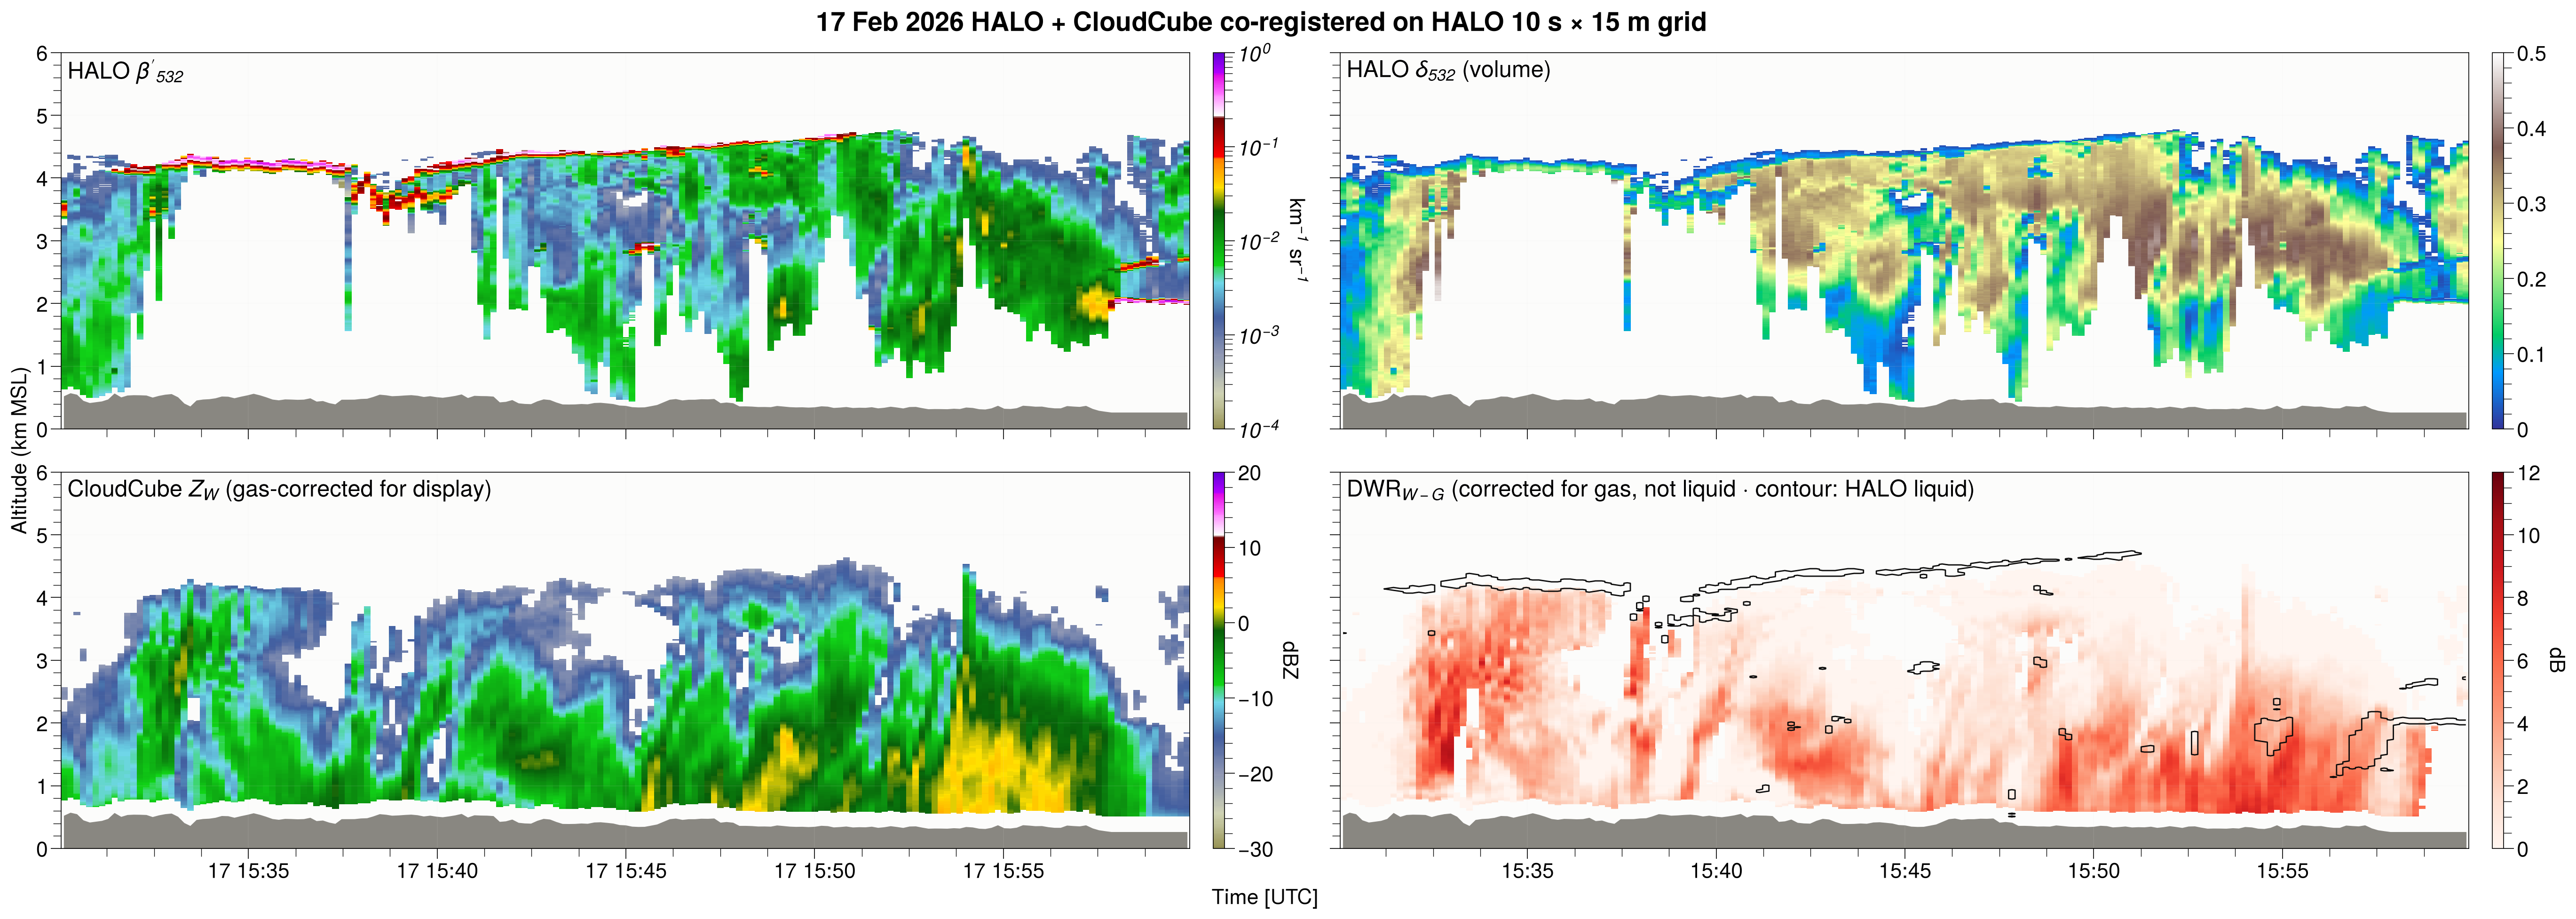

In [11]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"

panels = [
    ("532_total_attn_bsc", r"HALO $\beta'_{532}$", r"km$^{-1}$ sr$^{-1}$",
     dict(cmap="radar_NWSRefEnhanced", norm=mcolors.LogNorm(1e-4, 1e0)), [1e-4, 1e-3, 1e-2, 1e-1, 1e0]),
    ("532_dep", r"HALO $\delta_{532}$ (volume)", "",
     dict(cmap="terrain", norm=mcolors.Normalize(0, 0.5)), None),
    ("zm_w", r"CloudCube $Z_W$ (gas-corrected for display)", "dBZ",
     dict(cmap="radar_NWSRefEnhanced", norm=mcolors.Normalize(-30, 20)), None),
    ("dwr_wg_gc", r"DWR$_{W-G}$ (corrected for gas, not liquid · contour: HALO liquid)", "dB",
     dict(cmap="reds", norm=mcolors.Normalize(0, 12)), [0, 2, 4, 6, 8, 10, 12]),
     #dict(cmap=ramp(DIVERGING, "div"), norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-6, vmax=12)), [-6, -3, 0, 3, 6, 9, 12]),
]

fig, axs = uplt.subplots(nrows=2, ncols=2, refwidth=12, refaspect=3, sharex=True, sharey=True,
                         facecolor=SURFACE)
for ax, (var, title, units, kw, ticks) in zip(axs, panels):
    data = ds[var].values
    if var in "532_total_attn_bsc":
        data = np.where(ds["532_dep"] < 0.02, np.nan, data)
    elif var in "532_dep":
        data = np.where(ds["532_dep"] < 0.02, np.nan, data)
    elif var in ("zm_w", "dwr_wg_gc"):
        data = np.where(near_sfc, np.nan, data)
    m = ax.pcolormesh(t, zkm, data.T, discrete=False, **kw)
    cb = ax.colorbar(m, loc="r", label=units, width=0.12)
    if ticks is not None:
        cb.set_ticks(ticks)
        if var == "532_total_attn_bsc":
            cb.set_ticklabels([f"$10^{{{int(np.log10(v))}}}$" for v in ticks])
    ax.fill_between(t, 0, sfc, alpha=1., color=MUTED)
    #ax.plot(t, sfc, color=MUTED, lw=1.0)
    if var == "dwr_wg_gc":
        ax.contour(t, zkm, liquid.T, levels=[0.5], colors=INK, linewidths=1.0)
    ax.format(ultitle=title, facecolor=SURFACE, gridcolor=GRID)
axs.format(ylim=(0, ymax_km), ylabel="Altitude (km MSL)", xlabel="Time [UTC]",
           suptitle="17 Feb 2026 HALO + CloudCube co-registered on HALO 10 s × 15 m grid "
           )
axs.format(xrotation=0)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

/var/folders/js/9036d4cd7bs_z7lq3584lr380000gp/T/ipykernel_61024/2496676396.py:26: UltraPlotWarning: Skipping incompatible x-axis sharing for CartesianAxes and CartesianAxes: different axis unit domains.
  cb = ax.colorbar(m, loc="r", label=units, width=0.12)


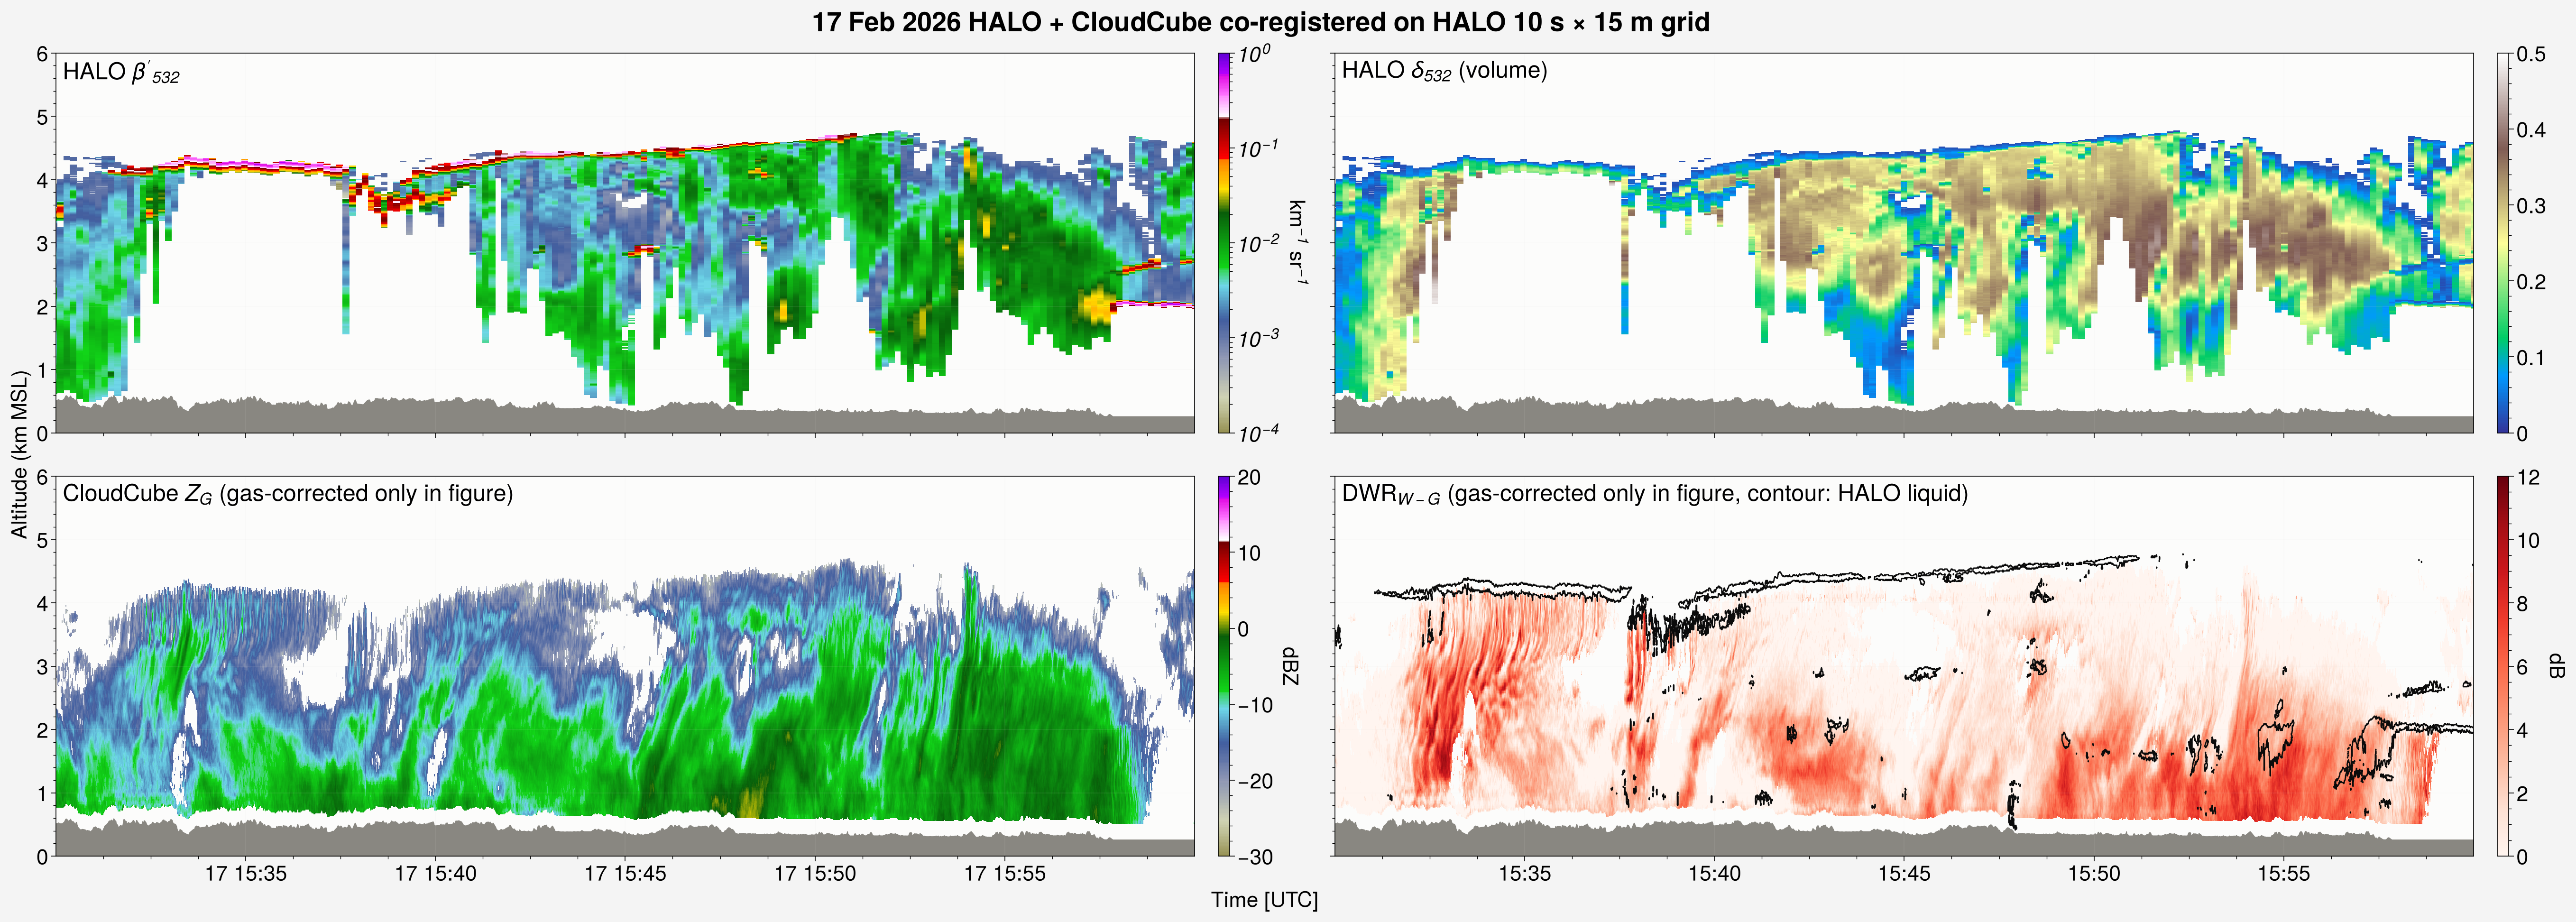

In [20]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"

panels = [
    ("532_total_attn_bsc", r"HALO $\beta'_{532}$", r"km$^{-1}$ sr$^{-1}$",
     dict(cmap="radar_NWSRefEnhanced", norm=mcolors.LogNorm(1e-4, 1e0)), [1e-4, 1e-3, 1e-2, 1e-1, 1e0]),
    ("532_dep", r"HALO $\delta_{532}$ (volume)", "",
     dict(cmap="terrain", norm=mcolors.Normalize(0, 0.5)), None),
    ("zgc_g", r"CloudCube $Z_G$ (gas-corrected only in figure)", "dBZ",
     dict(cmap="radar_NWSRefEnhanced", norm=mcolors.Normalize(-30, 20)), None),
    ("dwr_wg_gc", r"DWR$_{W-G}$ (gas-corrected only in figure, contour: HALO liquid)", "dB",
     dict(cmap="reds", norm=mcolors.Normalize(0, 12)), [0, 2, 4, 6, 8, 10, 12]),
     #dict(cmap=ramp(DIVERGING, "div"), norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-6, vmax=12)), [-6, -3, 0, 3, 6, 9, 12]),
]

fig, axs = uplt.subplots(nrows=2, ncols=2, refwidth=12, refaspect=3, sharex=True, sharey=True,
                         facecolor=SURFACE)
for ax, (var, title, units, kw, ticks) in zip(axs, panels):
    data = ds[var].values
    if var in "532_total_attn_bsc":
        data = np.where(ds["532_dep"] < 0.02, np.nan, data)
    elif var in "532_dep":
        data = np.where(ds["532_dep"] < 0.02, np.nan, data)
    elif var in ("zgc_g", "dwr_wg_gc"):
        data = np.where(near_sfc, np.nan, data)
    m = ax.pcolormesh(t, zkm, data.T, discrete=False, **kw)
    cb = ax.colorbar(m, loc="r", label=units, width=0.12)
    if ticks is not None:
        cb.set_ticks(ticks)
        if var == "532_total_attn_bsc":
            cb.set_ticklabels([f"$10^{{{int(np.log10(v))}}}$" for v in ticks])
    ax.fill_between(t, 0, sfc, alpha=1., color=MUTED)
    #ax.plot(t, sfc, color=MUTED, lw=1.0)
    if var == "dwr_wg_gc":
        ax.contour(t, zkm, liquid.T, levels=[0.5], colors=INK, linewidths=1.0)
    ax.format(ultitle=title, facecolor=SURFACE, gridcolor=GRID)
axs.format(ylim=(0, ymax_km), ylabel="Altitude (km MSL)", xlabel="Time [UTC]",
           suptitle="17 Feb 2026 HALO + CloudCube co-registered on HALO 10 s × 15 m grid "
           )
axs.format(xrotation=0)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

In [21]:
ds = xr.open_dataset(cache_dir() / "coreg_20260217_1530-1600.nc")
ymax_km=6.0
radar_clearance_m=250.0

t = ds["time"].values
zkm = ds["z"].values / 1000.0
liquid = ds["liquid"].values.astype(float)
sfc = ds["surface_alt_lidar"].to_series().interpolate(limit_direction="both").to_numpy() / 1000.0

# display-only: hide radar gates within radar_clearance_m of the lidar surface (surface clutter)
near_sfc = (zkm[None, :] - sfc[:, None]) * 1000.0 < radar_clearance_m

/var/folders/js/9036d4cd7bs_z7lq3584lr380000gp/T/ipykernel_61024/3223402483.py:26: UltraPlotWarning: Skipping incompatible x-axis sharing for CartesianAxes and CartesianAxes: different axis unit domains.
  cb = ax.colorbar(m, loc="r", label=units, width=0.12)


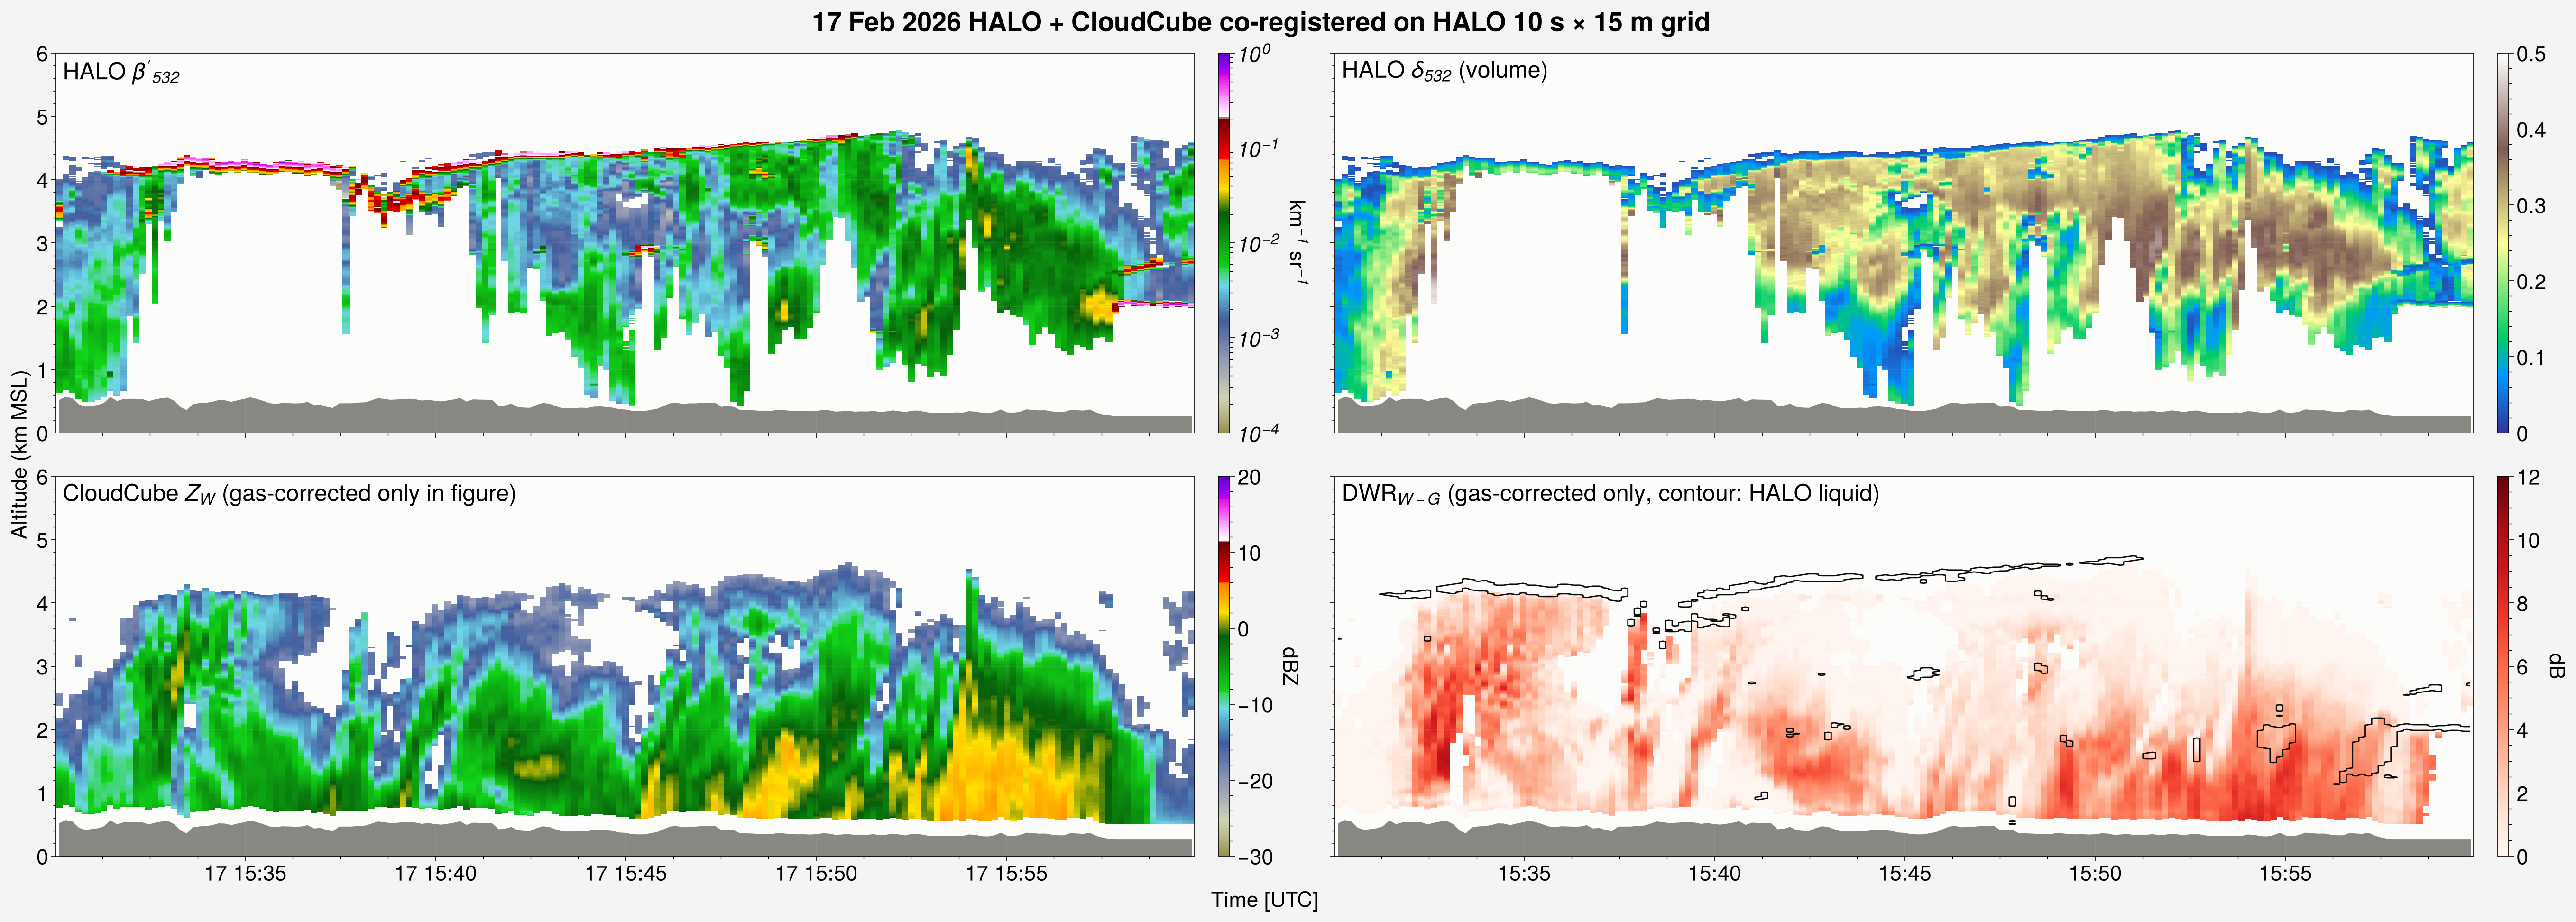

In [22]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"

panels = [
    ("532_total_attn_bsc", r"HALO $\beta'_{532}$", r"km$^{-1}$ sr$^{-1}$",
     dict(cmap="radar_NWSRefEnhanced", norm=mcolors.LogNorm(1e-4, 1e0)), [1e-4, 1e-3, 1e-2, 1e-1, 1e0]),
    ("532_dep", r"HALO $\delta_{532}$ (volume)", "",
     dict(cmap="terrain", norm=mcolors.Normalize(0, 0.5)), None),
    ("zgc_w", r"CloudCube $Z_W$ (gas-corrected only in figure)", "dBZ",
     dict(cmap="radar_NWSRefEnhanced", norm=mcolors.Normalize(-30, 20)), None),
    ("dwr_wg_gc", r"DWR$_{W-G}$ (gas-corrected only, contour: HALO liquid)", "dB",
     dict(cmap="reds", norm=mcolors.Normalize(0, 12)), [0, 2, 4, 6, 8, 10, 12]),
     #dict(cmap=ramp(DIVERGING, "div"), norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-6, vmax=12)), [-6, -3, 0, 3, 6, 9, 12]),
]

fig, axs = uplt.subplots(nrows=2, ncols=2, refwidth=12, refaspect=3, sharex=True, sharey=True,
                         facecolor=SURFACE)
for ax, (var, title, units, kw, ticks) in zip(axs, panels):
    data = ds[var].values
    if var in "532_total_attn_bsc":
        data = np.where(ds["532_dep"] < 0.02, np.nan, data)
    elif var in "532_dep":
        data = np.where(ds["532_dep"] < 0.02, np.nan, data)
    elif var in ("zgc_w", "dwr_wg_gc"):
        data = np.where(near_sfc, np.nan, data)
    m = ax.pcolormesh(t, zkm, data.T, discrete=False, **kw)
    cb = ax.colorbar(m, loc="r", label=units, width=0.12)
    if ticks is not None:
        cb.set_ticks(ticks)
        if var == "532_total_attn_bsc":
            cb.set_ticklabels([f"$10^{{{int(np.log10(v))}}}$" for v in ticks])
    ax.fill_between(t, 0, sfc, alpha=1., color=MUTED)
    #ax.plot(t, sfc, color=MUTED, lw=1.0)
    if var == "dwr_wg_gc":
        ax.contour(t, zkm, liquid.T, levels=[0.5], colors=INK, linewidths=1.0)
    ax.format(ultitle=title, facecolor=SURFACE, gridcolor=GRID)
axs.format(ylim=(0, ymax_km), ylabel="Altitude (km MSL)", xlabel="Time [UTC]",
           suptitle="17 Feb 2026 HALO + CloudCube co-registered on HALO 10 s × 15 m grid "
           )
axs.format(xrotation=0)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))